# MarineGuard AI — CleanSea Ablation

Train YOLO26n without the 193 CleanSea samples to assess their contribution. Preserve the original data and checkpoint.


## 1. Setup

Install dependencies and mount Drive.


In [3]:
%pip install -q "ultralytics==8.4.216" pyyaml pandas matplotlib pillow

In [4]:
from google.colab import drive
from pathlib import Path
from collections import Counter
from IPython.display import display
from ultralytics import YOLO
import os, random, hashlib, json, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics, torch

drive.mount('/content/drive')
print('Ultralytics:', ultralytics.__version__)
print('Torch:', torch.__version__)
print('GPU:', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '(CPU only)')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Ultralytics: 8.4.216
Torch: 2.14.1+cu130
GPU: True Tesla T4


## 2. Experiment paths

Identify the original dataset, model weights, and output directory.


In [5]:
DRIVE = Path('/content/drive/MyDrive')
ROOT = DRIVE / 'MarineGuard_YOLO' / 'MarineGuard_YOLO_Fixed'
OLD_BEST = (DRIVE / 'MarineGuard_Model_Selection' / 'budget20_30_v1'
            / 'runs_budget20_30_v1' / 'final/yolo26n/weights/best.pt')
OUT = DRIVE / 'MarineGuard_Model_Selection' / 'no_cleansea_manifest_ablation_v2'
OUT.mkdir(parents=True, exist_ok=True)
MANIFEST = OUT / 'train_without_cleansea.txt'
DATA = OUT / 'data_without_cleansea.yaml'
RUNS = OUT / 'runs'
RUN_NAME = 'yolo26n_fresh_30epochs'
TRAIN_DIR = RUNS / RUN_NAME
BEST = TRAIN_DIR / 'weights/best.pt'
LAST = TRAIN_DIR / 'weights/last.pt'
IMG = 640
BATCH = 8
SEED = 42

assert (ROOT / 'data.yaml').is_file(), f'Original data.yaml missing: {ROOT}'
for s in ('train','val','test'):
    assert (ROOT / 'images' / s).is_dir(), f'Images missing: {s}'
    assert (ROOT / 'labels' / s).is_dir(), f'Labels missing: {s}'
print('Original dataset:', ROOT)
print('Ablation results:', OUT)
print('Old checkpoint exists:', OLD_BEST.is_file())

Original dataset: /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed
Ablation results: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2
Old checkpoint exists: True


## 3. Training manifest

Build a manifest excluding CleanSea while retaining all other original training images.


In [6]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
def split_images(split):
    return sorted(p for p in (ROOT / 'images' / split).rglob('*')
                  if p.is_file() and p.suffix.lower() in IMG_EXT)

def label_for_image(img):
    rel = img.relative_to(ROOT / 'images')
    return (ROOT / 'labels' / rel).with_suffix('.txt')

original = {s:split_images(s) for s in ('train','val','test')}
cleansea = [p for p in original['train'] if p.stem.lower().startswith('cleansea_')]
no_cleansea = [p for p in original['train'] if not p.stem.lower().startswith('cleansea_')]
print('Original train images:',len(original['train']))
print('Excluded CleanSea images:',len(cleansea))
print('Remaining train images:',len(no_cleansea))
assert len(original['train']) == 2626 and len(cleansea) == 193 and len(no_cleansea) == 2433, (
    'Original dataset or CleanSea subset differs from expected. Investigate before proceeding.')
assert len(original['val']) == 178 and len(original['test']) == 214, 'Split counts changed!'

# Preserve absolute image paths; Ultralytics locates each label through
# the existing images/ and labels/ directory structure.
MANIFEST.write_text('\n'.join(str(p) for p in no_cleansea) + '\n',encoding='utf-8')

raw = yaml.safe_load((ROOT/'data.yaml').read_text(encoding='utf-8'))
names = raw['names']
if isinstance(names, dict): names=[names.get(i,names.get(str(i))) for i in (0,1)]
assert len(names)==2 and str(names[0]).lower()=='net' and str(names[1]).lower()=='rope', names

cfg={'path':str(ROOT),'train':str(MANIFEST),
     'val':'images/val','test':'images/test',
     'nc':2,'names':{0:'Net',1:'Rope'}}
DATA.write_text(yaml.safe_dump(cfg, sort_keys=False),encoding='utf-8')
print('\nExperiment YAML:')
print(DATA.read_text())
print('First 3 manifest lines:',MANIFEST.read_text().splitlines()[:3])

Original train images: 2626
Excluded CleanSea images: 193
Remaining train images: 2433

Experiment YAML:
path: /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed
train: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/train_without_cleansea.txt
val: images/val
test: images/test
nc: 2
names:
  0: Net
  1: Rope

First 3 manifest lines: ['/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/images/train/100.jpg', '/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/images/train/1027.jpg', '/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/images/train/1028.jpg']


## 4. Dataset audit

Verify label format, box geometry, image counts, and split separation.


In [7]:
def audit(split, images):
    counts=Counter(); missing=[]; bad=[]; empty=0; big=0
    for im in images:
        lab=label_for_image(im)
        if not lab.is_file(): missing.append(str(lab)); continue
        lines=[q.strip() for q in lab.read_text(encoding='utf-8').splitlines() if q.strip()]
        if not lines: empty+=1
        for line in lines:
            try:
                x=line.split()
                assert len(x)==5, 'not 5 YOLO columns'
                cls=int(x[0]); xc,yc,w,h=map(float,x[1:])
                assert cls in (0,1) and np.isfinite([xc,yc,w,h]).all(), 'invalid class/value'
                assert w>0 and h>0, 'non-positive size'
                assert xc-w/2>=-0.0001 and yc-h/2>=-0.0001, 'outside image (left/top)'
                assert xc+w/2<=1.0001 and yc+h/2<=1.0001, 'outside image (right/bottom)'
                counts[cls]+=1
                if w*h>.5:big+=1
            except Exception as e:bad.append(f'{lab.name}: {line} ({e})')
    return {'split':split,'images':len(images),'Net_instances':counts[0],
            'Rope_instances':counts[1],'missing_labels':len(missing),
            'empty_labels':empty,'large_boxes':big},missing,bad

rows=[]; errors=[]
for split,imgs in [('train (without CleanSea)',no_cleansea),
                   ('val',original['val']),('test',original['test'])]:
    row, missing, bad = audit(split,imgs)
    rows.append(row); errors+=missing+bad
AUDIT=pd.DataFrame(rows)
display(AUDIT)
if errors:
    print('First errors:')
    for x in errors[:10]: print(' -',x)
assert not errors, f'Audit found {len(errors)} errors in the ORIGINAL dataset. Do not train.'
assert rows[0]['Net_instances']==953 and rows[0]['Rope_instances']==1976, (
    'The no-CleanSea class counts differ from the expected original-minus-CleanSea counts.')
assert rows[1]['Net_instances']==7 and rows[1]['Rope_instances']==71
assert rows[2]['Net_instances']==127 and rows[2]['Rope_instances']==117

# Filename overlap checks do not establish site- or video-level separation.
for a,b in [('train','val'),('train','test'),('val','test')]:
    A=no_cleansea if a=='train' else original[a]
    B=no_cleansea if b=='train' else original[b]
    same={x.name for x in A} & {x.name for x in B}
    assert not same, f'Overlapping filenames {a}/{b}: {list(same)[:5]}'
print('AUDIT PASSED. Source files untouched; training manifest ready.')
print('LIMITATION: 7 Net instances in validation; source/video metadata still require independent verification.')

,split,images,Net_instances,Rope_instances,missing_labels,empty_labels,large_boxes
0,train (without CleanSea),2433,953,1976,0,500,383
1,val,178,7,71,0,100,2
2,test,214,127,117,0,0,5


AUDIT PASSED. Source files untouched; training manifest ready.
LIMITATION: 7 Net instances in validation; source/video metadata still require independent verification.


## 5. Ablation training

Train a new YOLO26n from pretrained weights; support resumption after interruption.


In [10]:

import random
import numpy as np
import torch
from pathlib import Path
from ultralytics import YOLO

# Resume the interrupted experiment from its saved training state.
TRAIN_MODE = "resume"  # Options: "new", "resume", "skip"

assert TRAIN_MODE in ("new", "resume", "skip")

print("Training mode:", TRAIN_MODE)
print("Run directory:", TRAIN_DIR)
print("Last checkpoint exists:", LAST.is_file())
print("Best checkpoint exists:", BEST.is_file())

if TRAIN_MODE != "skip":
    assert torch.cuda.is_available(), (
        "GPU unavailable. In Colab select "
        "Runtime > Change runtime type > T4 GPU."
    )

if TRAIN_MODE == "new":
    assert not TRAIN_DIR.exists(), (
        f"Experiment already exists: {TRAIN_DIR}. "
        "Use 'resume' or 'skip' instead."
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    model = YOLO("yolo26n.pt")

    model.train(
        data=str(DATA),
        epochs=30,
        patience=8,
        imgsz=IMG,
        batch=BATCH,
        optimizer="SGD",
        lr0=0.01,
        lrf=0.01,
        momentum=0.937,
        seed=SEED,
        deterministic=True,
        device=0,
        workers=2,
        hsv_h=0.01,
        hsv_s=0.30,
        hsv_v=0.20,
        translate=0.05,
        scale=0.20,
        fliplr=0.5,
        flipud=0.0,
        degrees=0.0,
        mosaic=0.30,
        close_mosaic=8,
        mixup=0.0,
        save=True,
        plots=True,
        project=str(RUNS),
        name=RUN_NAME,
        exist_ok=False,
        verbose=False
    )

elif TRAIN_MODE == "resume":
    assert LAST.is_file(), (
        f"Cannot resume: last.pt not found at {LAST}"
    )

    print("\nResuming YOLO26n from:", LAST)

    # Restores saved weights, optimizer, scheduler,
    # and training progress from the checkpoint.
    model = YOLO(str(LAST))
    model.train(resume=True)

elif TRAIN_MODE == "skip":
    assert BEST.is_file(), (
        f"Cannot skip: best.pt not found at {BEST}"
    )
    print("\nTraining skipped. Using existing model.")

assert BEST.is_file(), f"best.pt not found: {BEST}"

print("\nCheckpoint ready!")
print("Best checkpoint:", BEST)
print("Last checkpoint:", LAST)
print("Experiment folder:", TRAIN_DIR)


Training mode: resume
Run directory: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/runs/yolo26n_fresh_30epochs
Last checkpoint exists: True
Best checkpoint exists: True

Resuming YOLO26n from: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/runs/yolo26n_fresh_30epochs/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/data_without_cleansea.yaml, degrees=0.0, 

## 6. Training history

Review the training curve and the saved best checkpoint.


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
20,21,2325.61,1.12867,0.96521,0.01410,0.67469,0.54842,0.49280,0.29136,0.82443,1.21129,0.02198,0.00340,0.00340,0.00340
21,22,2405.57,1.10603,0.91634,0.01382,0.43185,0.56841,0.35801,0.16924,0.93463,1.25727,0.02620,0.00307,0.00307,0.00307
22,23,2488.10,1.01918,0.65416,0.01309,0.37228,0.28270,0.34478,0.15537,0.95569,1.27090,0.02677,0.00274,0.00274,0.00274
23,24,2566.26,0.98205,0.60950,0.01266,0.59003,0.61873,0.48848,0.27494,0.85873,1.09190,0.02413,0.00241,0.00241,0.00241
24,25,2646.83,0.95925,0.57573,0.01209,0.51361,0.65392,0.43078,0.23138,0.90832,1.22245,0.02619,0.00208,0.00208,0.00208


Recorded epochs: 25


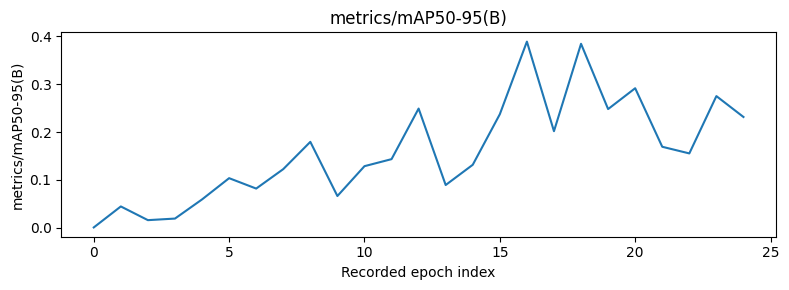

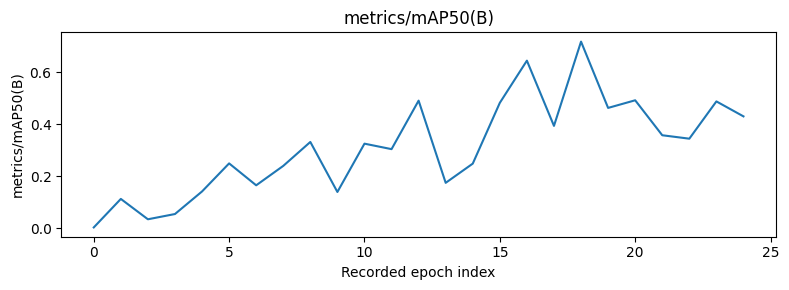

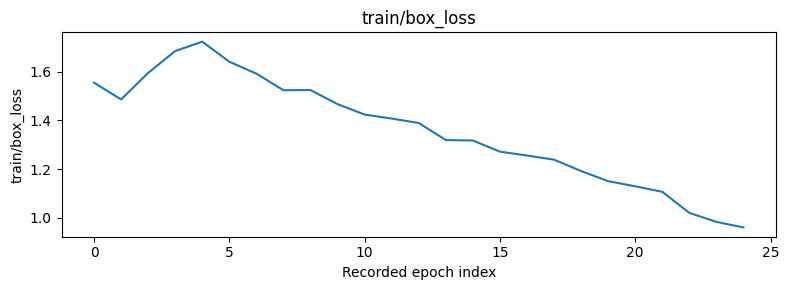

In [11]:
HIST=TRAIN_DIR/'results.csv'
if HIST.exists():
    h=pd.read_csv(HIST)
    display(h.tail(5))
    print('Recorded epochs:',len(h))
    for name in ['metrics/mAP50-95(B)','metrics/mAP50(B)','train/box_loss']:
        col=next((c for c in h.columns if c.strip()==name),None)
        if col:
            plt.figure(figsize=(8,3))
            plt.plot(h[col].to_numpy())
            plt.xlabel('Recorded epoch index');plt.ylabel(name);plt.title(name)
            plt.tight_layout();plt.show()
else:
    print('Training CSV not found:',HIST)

## 7. Original validation comparison

Evaluate both checkpoints on the same original validation split.


In [12]:
def evaluate(checkpoint,split,label):
    m=YOLO(str(checkpoint)).val(data=str(DATA),split=split,imgsz=IMG,
       device='cpu',batch=4,workers=0,conf=0.001,
       plots=True,project=str(OUT/'evaluation'/split),name=label,
       exist_ok=True,verbose=False)
    d={'model':label,'split':split,'mAP50':float(m.box.map50),
       'mAP50_95':float(m.box.map),'precision':float(m.box.mp),
       'recall':float(m.box.mr),'Net_mAP50_95':float(m.box.maps[0]),
       'Rope_mAP50_95':float(m.box.maps[1])}
    for pos,cid in enumerate(m.box.ap_class_index):
        label_cls='Net' if int(cid)==0 else 'Rope'
        d[label_cls+'_precision']=float(m.box.p[pos]);d[label_cls+'_recall']=float(m.box.r[pos])
    return d
rows=[evaluate(BEST,'val','new_without_CleanSea')]
if OLD_BEST.is_file():
    rows.append(evaluate(OLD_BEST,'val','original_with_CleanSea'))
else:
    print('Previous model not found; new model evaluated alone.')
VAL=pd.DataFrame(rows)
display(VAL.round(4))
VAL.to_csv(OUT/'validation_comparison.csv',index=False)
print('Saved:',OUT/'validation_comparison.csv')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 122.6±38.5 MB/s, size: 185.9 KB)
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/val.cache... 178 images, 100 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 39.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 2.9it/s 15.6s
                   all        178         78      0.838      0.509      0.662      0.387
Speed: 0.8ms preprocess, 68.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/evaluation/val/new_without_CleanSea
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,389,97

,model,split,mAP50,mAP50_95,precision,recall,Net_mAP50_95,Rope_mAP50_95,Net_precision,Net_recall,Rope_precision,Rope_recall
0,new_without_CleanSea,val,0.6617,0.3872,0.8376,0.5087,0.5219,0.2525,0.6752,0.8571,1.0000,0.1603
1,original_with_CleanSea,val,0.5334,0.3271,0.6972,0.6675,0.2994,0.3547,0.4501,0.8571,0.9443,0.4778


Saved: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/validation_comparison.csv


## 8. TrashCan comparison

Use TrashCan as an external-domain diagnostic, not an untouched final test.


In [13]:
RUN_EXTERNAL_TEST=True
if RUN_EXTERNAL_TEST:
    rows=[evaluate(BEST,'test','new_without_CleanSea')]
    if OLD_BEST.is_file(): rows.append(evaluate(OLD_BEST,'test','original_with_CleanSea'))
    TEST=pd.DataFrame(rows)
    display(TEST.round(5))
    TEST.to_csv(OUT/'trashcan_diagnostic_comparison.csv',index=False)
    print('Saved:',OUT/'trashcan_diagnostic_comparison.csv')
else:
    print('External test skipped.')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 3.9±7.6 ms, read: 1.4±3.1 MB/s, size: 24.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/test... 214 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 214/214 211.2it/s 1.0s
val: New cache created: /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 54/54 2.7it/s 19.9s
                   all        214        244    0.00663     0.0891    0.00106   0.000685
Speed: 1.4ms preprocess, 81.6ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /co

,model,split,mAP50,mAP50_95,precision,recall,Net_mAP50_95,Rope_mAP50_95,Net_precision,Net_recall,Rope_precision,Rope_recall
0,new_without_CleanSea,test,0.00106,0.00069,0.00663,0.08907,0.0008,0.00057,0.01163,0.01575,0.00164,0.16239
1,original_with_CleanSea,test,0.00513,0.00175,0.01594,0.04105,0.0014,0.00210,0.01731,0.03937,0.01458,0.04274


Saved: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/trashcan_diagnostic_comparison.csv


## 9. Prediction review

Compare ground truth and predicted boxes on selected external examples.


Ground truth and model prediction: tc_vid_000276_frame0000008.jpg


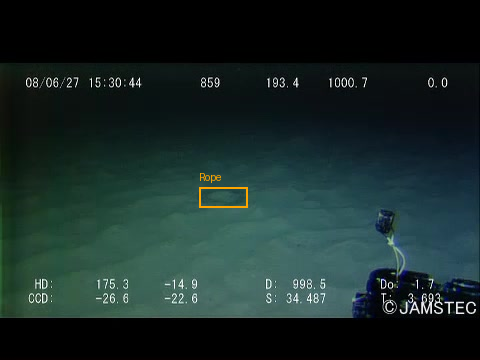

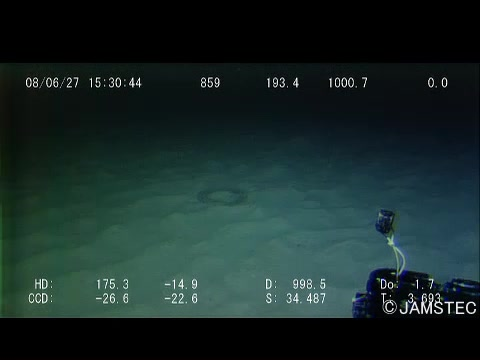

Ground truth and model prediction: tc_vid_000052_frame0000072.jpg


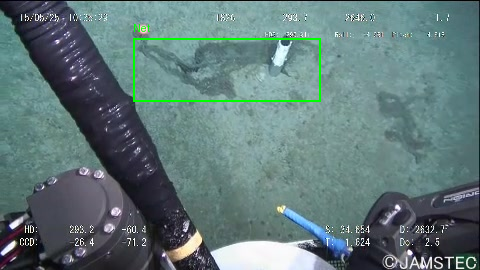

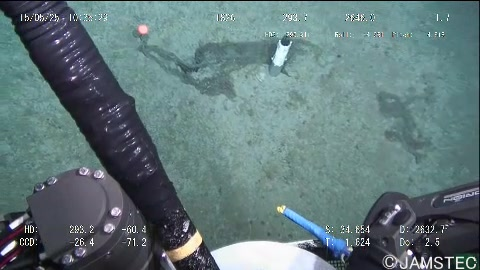

Ground truth and model prediction: tc_vid_000052_frame0000029.jpg


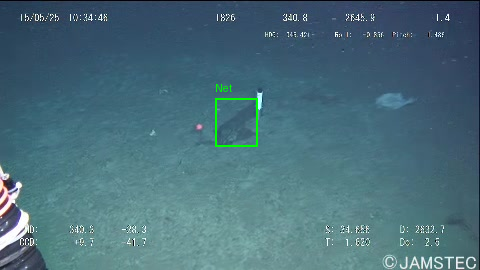

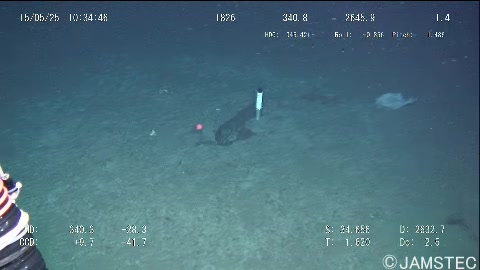

Ground truth and model prediction: tc_vid_000283_frame0000018.jpg


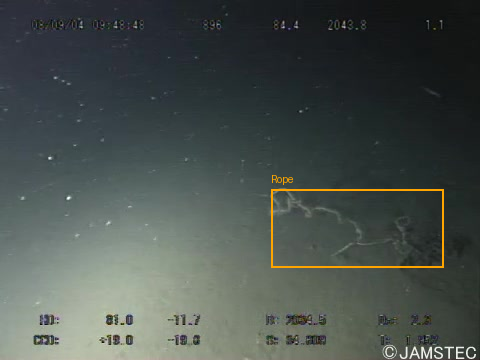

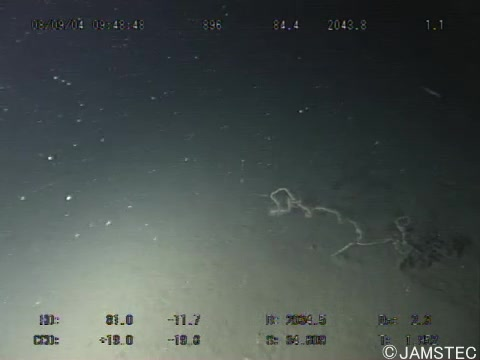

Ground truth and model prediction: tc_vid_000055_frame0000045.jpg


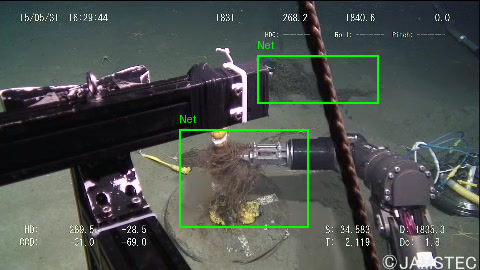

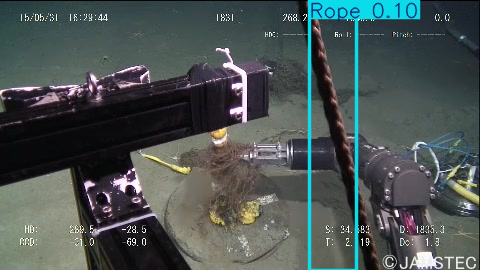

These low-confidence predictions are for VISUAL DIAGNOSIS only, not a retuned test score.


In [14]:
from PIL import Image,ImageDraw
from IPython.display import display
random.seed(SEED)
examples=random.sample(original['test'],min(5,len(original['test'])))
model=YOLO(str(BEST))
for img_path in examples:
    original_img=Image.open(img_path).convert('RGB')
    W,H=original_img.size
    gt=original_img.copy();draw=ImageDraw.Draw(gt)
    for line in label_for_image(img_path).read_text().splitlines():
        if not line.strip():continue
        cls,xc,yc,w,h=map(float,line.split())
        box=[(xc-w/2)*W,(yc-h/2)*H,(xc+w/2)*W,(yc+h/2)*H]
        color='lime' if int(cls)==0 else 'orange'
        draw.rectangle(box,outline=color,width=max(2,W//300))
        draw.text((max(0,box[0]),max(0,box[1]-16)), 'Net' if int(cls)==0 else 'Rope',fill=color)
    r=model.predict(source=str(img_path),imgsz=IMG,conf=0.10,
                    device='cpu',verbose=False)[0]
    # Convert the plotted prediction from BGR to RGB for PIL display.
    pred=Image.fromarray(r.plot()[...,::-1])
    gt.thumbnail((700,700));pred.thumbnail((700,700))
    print('Ground truth and model prediction:',img_path.name)
    display(gt,pred)
print('These low-confidence predictions are for VISUAL DIAGNOSIS only, not a retuned test score.')

## 10. Experiment record

Save configuration, dataset counts, and checkpoint references.


In [15]:
metadata={
 'experiment':'YOLO26n data ablation: original vs original minus CleanSea',
 'original_dataset_root':str(ROOT),
 'trained_on':str(MANIFEST),
 'excluded_cleansea_images':len(cleansea),
 'training_images':len(no_cleansea),
 'validation_images':len(original['val']),
 'test_images':len(original['test']),
 'new_checkpoint':str(BEST),
 'old_checkpoint':str(OLD_BEST) if OLD_BEST.is_file() else None,
 'input_size':IMG,'batch_size':BATCH,'seed':SEED,
 'max_epochs':30,'optimizer':'SGD','ultralytics':ultralytics.__version__,
 'limitations':['7 validation Net instances',
                'Original TrashCan test already seen during error analysis',
                'Original site/video separation not independently verified']}
(OUT/'experiment_manifest.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
AUDIT.to_csv(OUT/'dataset_audit.csv',index=False)
print('Done. Files in:',OUT)
print('Best checkpoint:',BEST)
print('Compare validation_comparison.csv first; TrashCan results are diagnostic.')

Done. Files in: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2
Best checkpoint: /content/drive/MyDrive/MarineGuard_Model_Selection/no_cleansea_manifest_ablation_v2/runs/yolo26n_fresh_30epochs/weights/best.pt
Compare validation_comparison.csv first; TrashCan results are diagnostic.


## Ablation outcome

Removing CleanSea increased overall original-validation mAP50–95 from 0.3271 to 0.3872, but Rope recall fell from 0.4778 to 0.1603. External mAP remained near zero. These results did not justify replacing the original checkpoint.
